# 1. Problem

Recover a Gaussian-resolved Mn core-loss single-scattering spectrum from paired **real measured** low-loss and core-loss spectra. Plural scattering mixes the core edge with the measured low-loss distribution. The benchmark preserves the author's complete selected spectral window; no synthetic observations replace the measurements.

The released eXSpy0.3.2 implementation supplies an independently executed numerical comparator, **not experimental ground truth**. We compare the original example's no-op alignment call separately from a valid paired-alignment API call. Neither historical paper plots nor a precomputed local result substitutes for the active reconstruction below.

In [1]:
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
root=Path.cwd()
if not (root/'src').exists():root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_observations
from src.solvers import reconstruct
from src.visualization import show_observations,show_results
low,core=load_observations(root/'data/raw_data.npz')
upstream=dict(np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False))
old=dict(np.load(root/'notebooks/reference_outputs/original_example_noop.npz',allow_pickle=False))
print('Original count arrays:',low.shape,core.shape,low.dtype,core.dtype)

Original count arrays: (2048,) (2048,) float64 float64


# 2. Data

The paired spectrum files record 4 September 2012, with 2048 bins of width 0.2 eV and nominal origins −40 eV and 360 eV. Counts remain float64, including recorded negative noise. The visible zero-loss maximum supplies a +0.8 eV offset, subtracted from **both energy axes**. No shift is fitted using a hidden core target. The continuum is calibrated on the corrected 600–638 eV interval.

# 3. Physics

With elastic count $I_0$, tapered measured low-loss count kernel $L$, background-subtracted core counts $V$ and Gaussian density $G$, the finite-window model is

$$L\circledast S=I_0\,G\circledast V.$$

Here $\circledast$ is length-3000 circular discrete convolution without an extra bin-width factor, $S$ is the Gaussian-resolved spectral density in counts/eV, $G$ has units 1/eV and sampled integral $0.2\sum G\simeq1$. $I_0$ is the visible elastic-area count, **not the full low-loss total**. The continuum is $b(E)=0.2 A E^{-r}$ counts/channel. A cubic-spline half-maximum width $W$ sets $\sigma=W/2.3548$ eV. The README fixes the complete two-area continuum and finite-window boundary protocol.

# 4. Method

The active local path freshly calibrates both axes, evaluates the two-area continuum, appends the original method's 100-bin tails, applies Hann boundaries, determines the elastic count and measured resolution, then evaluates the Fourier-ratio inverse. It uses NumPy/SciPy mathematical primitives and **no upstream domain package**.

$$S=I_0\,\mathcal F^{-1}\left[\frac{\mathcal F(G)\mathcal F(V)}{\mathcal F(L)}\right].$$

No iterative stopping rule, image prior or positivity clipping is introduced. The original example passes a single signal to an API expecting a list, so its alignment is a no-op. Our reproduced corrected source call uses `also_align=[core_loss]`, with unchanged counts and corrected energies. Both outcomes are kept as labeled comparisons; the corrected physical definition is the benchmark target.

ACTIVE full844-channel reconstruction runtime: 0.001421 s
{'background_A': 2071918180231.7673, 'background_r': 2.6413222842269137, 'threshold': 9.0, 'fwhm': 3.1489655680913318, 'I0': 781556.1226593249}


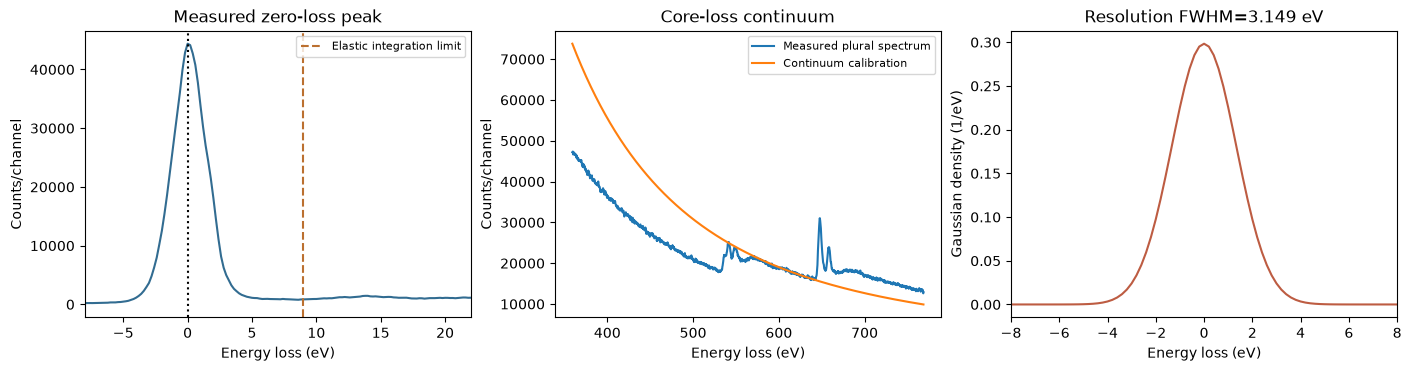

In [2]:
started=time.perf_counter()
fresh=reconstruct(low,core)
runtime=time.perf_counter()-started
np.savez(root/'output/reconstruction.npz',reconstruction=fresh['reconstruction'][None])
print(f'ACTIVE full844-channel reconstruction runtime: {runtime:.6f} s')
print({k:float(fresh[k]) for k in ['background_A','background_r','threshold','fwhm','I0']})
display(show_observations(low,core,fresh));plt.close('all')

# 5. Results

The source example compares the continuum-subtracted plural edge against the deconvolved edge after normalization. We preserve that comparison and add absolute-intensity plots, source parity, energy-calibration diagnostics and a physical convolution check. There is no unbroadened ground-truth claim.

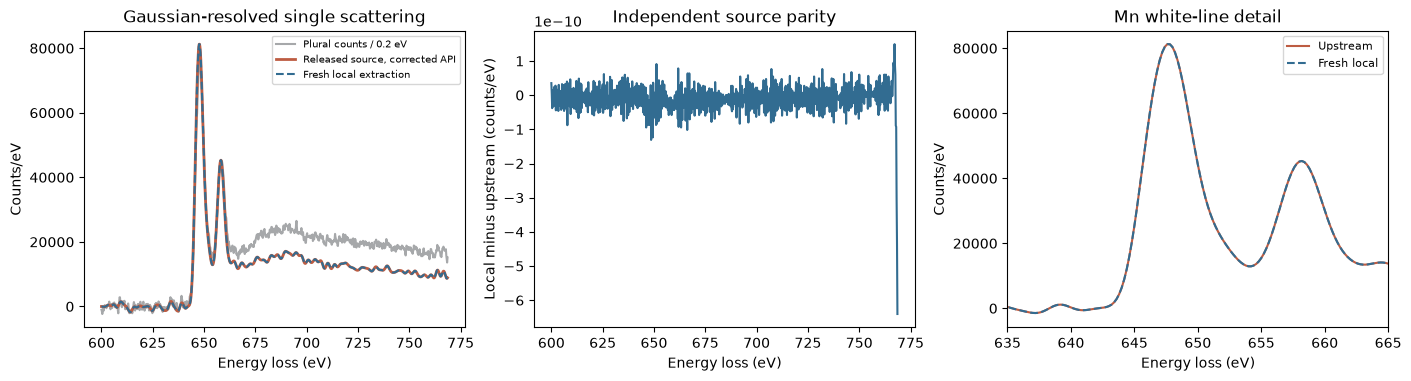

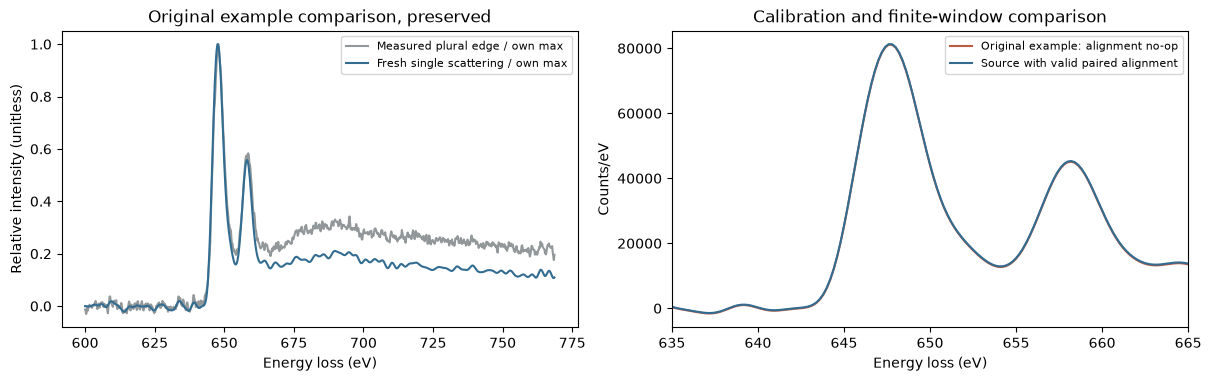

In [3]:
display(show_results(fresh,upstream));plt.close('all')
energy=600+.2*np.arange(844)
fig,ax=plt.subplots(1,2,figsize=(12,3.7),layout='constrained')
plural=fresh['edge'];ssd=fresh['reconstruction']
ax[0].plot(energy,plural/plural.max(),color='#92989a',label='Measured plural edge / own max')
ax[0].plot(energy,ssd/ssd.max(),color='#326c91',label='Fresh single scattering / own max')
ax[0].set(xlabel='Energy loss (eV)',ylabel='Relative intensity (unitless)',title='Original example comparison, preserved');ax[0].legend(fontsize=8)
ax[1].plot(600+.2*np.arange(len(old['reconstruction'])),old['reconstruction'],label='Original example: alignment no-op',color='#bd5c42')
ax[1].plot(energy,upstream['reconstruction'],label='Source with valid paired alignment',color='#326c91')
ax[1].set(xlim=(635,665),xlabel='Energy loss (eV)',ylabel='Counts/eV',title='Calibration and finite-window comparison');ax[1].legend(fontsize=8)
display(fig);plt.close('all')

| Measurement | Value |
|---|---:|
| Fresh runtime (s) | 0.001421 |
| Source parity max absolute (counts/eV) | 6.40284270048e-10 |
| Dynamic-range NRMSE | 5.41407501056e-16 |
| Relative integrated-intensity error | 7.46119439729e-16 |


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "nrmse": 5.414075010560264e-16,
    "relative_integral_error": 7.461194397286418e-16
  },
  "thresholds": {
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "relative_integral_error": {
      "comparison": "<=",
      "boundary": 1e-05
    }
  },
  "errors": []
}
Independent time-domain full3000 convolution relative residual: 4.319593868059301e-15


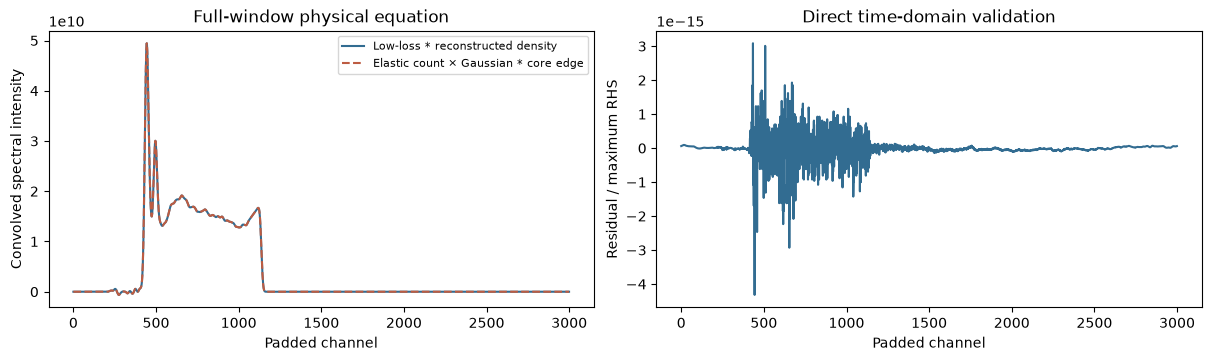

In [4]:
import importlib.util
spec=importlib.util.spec_from_file_location('independent_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,code=judge.evaluate(root/'output/reconstruction.npz')
(root/'output/judge_report.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
assert code==0,report
diff=fresh['reconstruction']-upstream['reconstruction']
display(Markdown('| Measurement | Value |\n|---|---:|\n'+
f'| Fresh runtime (s) | {runtime:.6f} |\n'+
f'| Source parity max absolute (counts/eV) | {np.max(abs(diff)):.12g} |\n'+
f"| Dynamic-range NRMSE | {report['metrics']['nrmse']:.12g} |\n"+
f"| Relative integrated-intensity error | {report['metrics']['relative_integral_error']:.12g} |\n"))
print(json.dumps(report,indent=2))
n=fresh['nfft'];L=np.pad(fresh['low_tapered'],(0,n-len(fresh['low_tapered'])));V=np.pad(fresh['core_tapered'],(0,n-len(fresh['core_tapered'])))
def circular(a,b):return sum(a[j]*np.roll(b,j) for j in range(n))
lhs=circular(L,fresh['full_reconstruction']);rhs=fresh['I0']*circular(fresh['gaussian'],V)
relative=np.max(abs(lhs-rhs))/np.max(abs(rhs))
print('Independent time-domain full3000 convolution relative residual:',relative)
assert relative<1e-11
fig,ax=plt.subplots(1,2,figsize=(12,3.5),layout='constrained')
ax[0].plot(lhs,label='Low-loss * reconstructed density',color='#326c91');ax[0].plot(rhs,ls='--',label='Elastic count × Gaussian * core edge',color='#bd5c42');ax[0].set(xlabel='Padded channel',ylabel='Convolved spectral intensity',title='Full-window physical equation');ax[0].legend(fontsize=8)
ax[1].plot((lhs-rhs)/np.max(abs(rhs)),color='#326c91');ax[1].set(xlabel='Padded channel',ylabel='Residual / maximum RHS',title='Direct time-domain validation')
display(fig);plt.close('all')

# 6. Conclusion

The fresh local implementation reproduces the valid released-source calculation at the specified Gaussian resolution, preserves original measured precision and absolute elastic-count scaling, and satisfies an independently evaluated time-domain convolution equation. The original no-op alignment and corrected API produce nearly overlapping white-line curves: the low-loss kernel and Gaussian origins largely cancel a shared energy shift in the ratio. Continuum calibration and finite-window selection still differ. The independent check that the observed zero-loss maximum has corrected energy zero establishes the selected energy convention; the comparison does not establish a large output peak shift.

Numerical parity establishes extraction fidelity, not physical truth. Finite-window continuation, the empirical power-law continuum and measured Gaussian resolution define this target; a different resolution or continuum would be a different quantity. No independently measured unbroadened single-scattering spectrum is available. The standard Judge accepts a nonzero numerical error margin and evaluates all844 channels without fitted shifts or rescaling.